# LoEC — Đối chứng SSP và ablation LCM
Dựa trên [notebookf7987d0818, phiên bản 2](https://www.kaggle.com/code/thidngminh/notebookf7987d0818) (Apache 2.0).

Trên Kaggle, bật GPU, gắn cùng năm bộ dữ liệu như notebook nguồn, rồi Run All. Chạy nhanh với `EPOCHS=1` và số episode nhỏ để kiểm tra; chạy chính thức với cấu hình mặc định. Khi môi trường chưa có trọng số ImageNet của ResNet-50, bật Internet hoặc dùng cache có sẵn.

- **Hiệu ứng LoEC** = SSP + LEM + LCM trừ SSP thuần.
- **Hiệu ứng LEM** = SSP + LEM trừ SSP thuần.
- **Hiệu ứng LCM** = cùng checkpoint có LEM, bật so với tắt LCM.
- **Hiệu ứng độ đo** = Cosine trừ Euclidean tại cùng k và cùng quy tắc cập nhật.
- **Hiệu ứng k** = k=3 trừ k=1 tại cùng độ đo và cùng quy tắc cập nhật.

k là số patch neo của LCM. N_SHOT là số ảnh support. Thiết lập mặc định là 1-shot. Các mức được đặt trước cho ablation; tránh chọn cấu hình trên tập đích rồi báo chính điểm đó như kết quả xác nhận độc lập.

## 1. Khởi Tạo Môi Trường & Seed


In [1]:
import os
import glob
import random
import time
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import torchvision.transforms.functional as TF

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"[*] Thiết bị đang dùng: {device}")
if torch.cuda.is_available():
    print(f"[*] GPU: {torch.cuda.get_device_name(0)}")
    print(f"[*] VRAM khả dụng: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)
print("[✓] Seed đã cố định tại 42.")


[*] Thiết bị đang dùng: cuda
[*] GPU: Tesla T4
[*] VRAM khả dụng: 15.64 GB
[✓] Seed đã cố định tại 42.


## 2. Backbone ResNet-50 (SSP Modified)
Trích xuất `layer0` (stem), `layer1`, `layer2`, `layer3` (với dilation cho layer3 để giữ độ phân giải không gian).


In [2]:
import types

class ResNet50_LoEC(nn.Module):
    def __init__(self, pretrained=True):
        super(ResNet50_LoEC, self).__init__()
        weights = models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
        base = models.resnet50(weights=weights)

        self.conv1 = base.conv1
        self.bn1 = base.bn1
        self.relu = base.relu
        self.maxpool = base.maxpool
        self.layer1 = base.layer1
        self.layer2 = base.layer2
        self.layer3 = base.layer3

        # 1. Dilation cho layer3 theo chuẩn FSS/SSP
        for n, m in self.layer3.named_modules():
            if 'conv2' in n:
                m.dilation = (2, 2)
                m.padding = (2, 2)
                m.stride = (1, 1)
            elif 'downsample.0' in n:
                m.stride = (1, 1)

        # 2. Bỏ ReLU cuối cùng của layer3 (Mục 4.2 bài báo: 'discard the last backbone stage and the last ReLU')
        last_block = self.layer3[-1]
        def _forward_no_last_relu(block_self, x):
            identity = x
            out = block_self.relu(block_self.bn1(block_self.conv1(x)))
            out = block_self.relu(block_self.bn2(block_self.conv2(out)))
            out = block_self.bn3(block_self.conv3(out))
            if block_self.downsample is not None:
                identity = block_self.downsample(x)
            out += identity
            return out  # Không qua ReLU cuối để giữ toàn bộ miền giá trị cho Cosine Similarity
        last_block.forward = types.MethodType(_forward_no_last_relu, last_block)

    def forward(self, x):
        pass


## 3. LCM cho thí nghiệm đối chứng
Mọi cấu hình giữ cùng patch 16×16, RGB trung bình, cách chọn patch neo, chuẩn hóa min–max theo từng neo và trọng số hiệu chỉnh. Cosine dùng khoảng cách 1 − cosine. Euclidean đo khoảng cách L2 trên RGB gốc của patch. LCM lấy trung bình qua k neo để k=3 không tự tăng hệ số hiệu chỉnh. Dạng cộng và dạng nhân đều được chạy cho mọi cặp độ đo và k. Đây là thiết lập ablation có kiểm soát, với công thức chuẩn hóa và gộp neo được thống nhất cho phép so sánh này.

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class SSP_MatchingNet(nn.Module):
    def __init__(self, pretrained=True, refine=False):
        super(SSP_MatchingNet, self).__init__()
        backbone = ResNet50_LoEC(pretrained=pretrained)
        self.layer0 = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool)
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.refine = refine

        # Đóng băng tham số của layer0 và layer1 (theo LoEC.py dòng 27-40 & Bảng 1 bài báo)
        for p in self.layer0.parameters():
            p.requires_grad = False
        for p in self.layer1.parameters():
            p.requires_grad = False

    def train(self, mode=True):
        super(SSP_MatchingNet, self).train(mode)
        # Giữ layer0, layer1 và các tầng BatchNorm ở chế độ eval() theo chuẩn FSS/SSP
        self.layer0.eval()
        self.layer1.eval()
        for m in self.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()
        return self

    # -------------------------------------------------------------
    # LEM: Low-level Enhancement Module (LoEC.py dòng 255)
    # -------------------------------------------------------------
    def feat_RCfourier_bias(self, feat, b, h, w, in_channels, out_channels, kernel_size=3):
        random_convolution = nn.Conv2d(
            b * in_channels, b * out_channels, kernel_size, 
            padding=kernel_size // 2, groups=b, bias=True
        ).to(feat.device)
        torch.nn.init.kaiming_normal_(random_convolution.weight, mode="fan_in", nonlinearity="relu")

        feat_reshaped = feat.view(1, b * in_channels, h, w)
        feat_RC = random_convolution(feat_reshaped)
        feat_RC = feat_RC.view(b, out_channels, h, w)

        try:
            autocast_off = torch.amp.autocast(feat.device.type, enabled=False)
        except (AttributeError, TypeError):
            autocast_off = torch.cuda.amp.autocast(enabled=False)

        with autocast_off:
            feat_fp32 = feat.float()
            feat_RC_fp32 = feat_RC.float()
            fft_src = torch.fft.rfft2(feat_fp32, norm="backward")
            fft_trg = torch.fft.rfft2(feat_RC_fp32, norm="backward")

            amp_trg = torch.abs(fft_trg)
            pha_src = torch.angle(fft_src)
            real_part = amp_trg * torch.cos(pha_src)
            imag_part = amp_trg * torch.sin(pha_src)
            fft_mix = torch.complex(real_part, imag_part)

            out_lem = torch.fft.irfft2(fft_mix, s=(h, w), norm="backward")
            return out_lem.to(feat.dtype)

    def masked_average_pooling(self, feature, mask):
        mask_interp = F.interpolate(mask.unsqueeze(1), size=feature.shape[-2:], mode="bilinear", align_corners=True)
        masked_feat = feature * mask_interp
        return masked_feat.sum(dim=(-2, -1)) / (mask_interp.sum(dim=(-2, -1)) + 1e-5)

    def similarity_func(self, feature_q, fg_proto, bg_proto):
        similarity_fg = F.cosine_similarity(feature_q, fg_proto, dim=1)
        similarity_bg = F.cosine_similarity(feature_q, bg_proto, dim=1)
        out = torch.cat((similarity_bg[:, None, ...], similarity_fg[:, None, ...]), dim=1) * 10.0
        return out

    # -------------------------------------------------------------
    # LCM: Hỗ trợ cả Cosine Similarity (Bài báo) & Euclidean (LoEC.py)
    # -------------------------------------------------------------
    def mask_correction(self, out, q_ori, patch_size=16, K=3, method='cosine'):
        """So sánh các patch theo cùng cách chuẩn hóa cho mọi độ đo."""
        if q_ori.dim() == 4 and q_ori.shape[1] == 3:
            q_ori = q_ori.permute(0, 2, 3, 1)

        b, h, w = out.shape[0], out.shape[2], out.shape[3]
        out_confidence = out[:, 1, :, :] - out[:, 0, :, :]  # Eq. (7): C(i, j) = S(i, j, 1) - S(i, j, 0)

        num_patches_x = h // patch_size
        num_patches_y = w // patch_size
        patch_confidence = out_confidence.view(b, num_patches_x, patch_size, num_patches_y, patch_size).permute(0, 1, 3, 2, 4)
        patch_confidence_means = patch_confidence.mean(dim=(3, 4))  # Eq. (8): Patch pooling C_p

        total_patches = num_patches_x * num_patches_y
        k_val = min(K, total_patches)
        # Eq. (9): Chọn Top-K patch tin cậy nhất
        _, top_indices = torch.topk(patch_confidence_means.view(b, -1), k=k_val, dim=1, largest=True, sorted=True)

        reshaped_image = q_ori.reshape(b, num_patches_x, patch_size, num_patches_y, patch_size, 3).permute(0, 1, 3, 2, 4, 5)
        patch_means = reshaped_image.to(torch.float32).mean(dim=(3, 4))
        patch_means_reshaped = patch_means.view(b, -1, 3)  # [B, N, 3]

        anchors = torch.gather(
            patch_means_reshaped, 1, top_indices.unsqueeze(-1).expand(-1, -1, 3)
        )
        if method == 'cosine':
            anchor_norm = F.normalize(anchors + 1e-7, dim=-1)
            patch_norm = F.normalize(patch_means_reshaped + 1e-7, dim=-1)
            distance = 1 - torch.bmm(anchor_norm, patch_norm.transpose(1, 2)).clamp(-1, 1)
        elif method == 'euclidean':
            distance = torch.linalg.vector_norm(
                anchors.unsqueeze(2) - patch_means_reshaped.unsqueeze(1), dim=-1
            )
        else:
            raise ValueError(f"Độ đo LCM không hợp lệ: {method}")

        # Cùng ánh xạ khoảng cách sang độ tương đồng [0, 1] cho cả hai độ đo.
        nearest = distance.amin(dim=-1, keepdim=True)
        span = distance.amax(dim=-1, keepdim=True) - nearest
        similarity = 1 - (distance - nearest) / span.clamp_min(1e-6)
        top_k_similarity_map = similarity.reshape(b, k_val, num_patches_x, num_patches_y)

        return top_indices, top_k_similarity_map

    def apply_lcm(self, logits, query_rgb, method, k, update, weight=0.6, bias=0.7):
        _, maps = self.mask_correction(logits, query_rgb, patch_size=16, K=k, method=method)
        delta = weight * (F.interpolate(maps, logits.shape[-2:], mode='nearest').mean(dim=1) - bias)
        scores = logits.clone()
        if update == 'additive':
            scores[:, 1] += delta
        elif update == 'multiplicative':
            scores[:, 1] *= 1 + delta
        else:
            raise ValueError(f"Quy tắc cập nhật LCM không hợp lệ: {update}")
        return scores

    # -------------------------------------------------------------
    # Self-Support Prototype Function (Khớp chuẩn LoEC.py dòng 178-240)
    # -------------------------------------------------------------
    def SSP_func(self, feature_q, out):
        bs = feature_q.shape[0]
        pred_1 = out.softmax(1).view(bs, 2, -1)
        pred_fg = pred_1[:, 1]
        pred_bg = pred_1[:, 0]

        fg_ls, bg_ls = [], []
        fg_local_ls, bg_local_ls = [], []

        for epi in range(bs):
            fg_thres = 0.7
            bg_thres = 0.6
            cur_feat = feature_q[epi].view(feature_q.shape[1], -1)
            f_h, f_w = feature_q[epi].shape[-2:]

            if (pred_fg[epi] > fg_thres).sum() > 0:
                fg_feat = cur_feat[:, (pred_fg[epi] > fg_thres)]
            else:
                fg_feat = cur_feat[:, torch.topk(pred_fg[epi], 12).indices]

            if (pred_bg[epi] > bg_thres).sum() > 0:
                bg_feat = cur_feat[:, (pred_bg[epi] > bg_thres)]
            else:
                bg_feat = cur_feat[:, torch.topk(pred_bg[epi], 12).indices]

            fg_proto = fg_feat.mean(-1)
            bg_proto = bg_feat.mean(-1)
            fg_ls.append(fg_proto.unsqueeze(0))
            bg_ls.append(bg_proto.unsqueeze(0))

            fg_feat_norm = fg_feat / (torch.norm(fg_feat, 2, 0, True) + 1e-8)
            bg_feat_norm = bg_feat / (torch.norm(bg_feat, 2, 0, True) + 1e-8)
            cur_feat_norm = cur_feat / (torch.norm(cur_feat, 2, 0, True) + 1e-8)

            cur_feat_norm_t = cur_feat_norm.t()
            fg_sim = (torch.matmul(cur_feat_norm_t, fg_feat_norm) * 2.0).softmax(-1)
            bg_sim = (torch.matmul(cur_feat_norm_t, bg_feat_norm) * 2.0).softmax(-1)

            fg_proto_local = torch.matmul(fg_sim, fg_feat.t()).t().view(-1, f_h, f_w).unsqueeze(0)
            bg_proto_local = torch.matmul(bg_sim, bg_feat.t()).t().view(-1, f_h, f_w).unsqueeze(0)

            fg_local_ls.append(fg_proto_local)
            bg_local_ls.append(bg_proto_local)

        # Định dạng tensor prototype chuẩn 4D [B, 1024, 1, 1] để broadcast chính xác
        new_fg = torch.cat(fg_ls, 0).unsqueeze(-1).unsqueeze(-1)
        new_bg = torch.cat(bg_ls, 0).unsqueeze(-1).unsqueeze(-1)
        new_fg_local = torch.cat(fg_local_ls, 0).unsqueeze(-1).unsqueeze(-1)
        new_bg_local = torch.cat(bg_local_ls, 0)

        return new_fg, new_bg, new_fg_local, new_bg_local

    def forward(self, img_s_list, mask_s_list, img_q, mask_q=None, 
                use_mask_correction=False, mask_k=0.6, mask_b=0.7, q_ori=None, use_lem=True,
                lcm_method='cosine', lcm_k=3, lcm_update_mode='additive'):
        b, h, w = img_q.shape[0], img_q.shape[2], img_q.shape[3]

        # 1. Trích xuất đặc trưng Support Images
        feature_s_list = []
        for k in range(len(img_s_list)):
            with torch.no_grad():
                s_0 = self.layer0(img_s_list[k])
                if self.training and use_lem:
                    s_0 = self.feat_RCfourier_bias(s_0, b, s_0.shape[2], s_0.shape[3], s_0.shape[1], s_0.shape[1], 3)
                s_0 = self.layer1(s_0)
            s_0 = self.layer2(s_0)
            s_0 = self.layer3(s_0)
            feature_s_list.append(s_0)

        # 2. Trích xuất đặc trưng Query Image
        with torch.no_grad():
            q_0 = self.layer0(img_q)
            q_0 = self.layer1(q_0)
        q_0 = self.layer2(q_0)
        feature_q = self.layer3(q_0)

        # 3. Trích xuất Prototype từ Support & tính Support Self-Similarity khi train
        feature_fg_list, feature_bg_list = [], []
        supp_out_ls = []
        for k in range(len(img_s_list)):
            feature_fg = self.masked_average_pooling(feature_s_list[k], (mask_s_list[k] == 1).float())[None, :]
            feature_bg = self.masked_average_pooling(feature_s_list[k], (mask_s_list[k] == 0).float())[None, :]
            feature_fg_list.append(feature_fg)
            feature_bg_list.append(feature_bg)

            if self.training:
                supp_sim_fg = F.cosine_similarity(feature_s_list[k], feature_fg.squeeze(0)[..., None, None], dim=1)
                supp_sim_bg = F.cosine_similarity(feature_s_list[k], feature_bg.squeeze(0)[..., None, None], dim=1)
                supp_out = torch.cat((supp_sim_bg[:, None, ...], supp_sim_fg[:, None, ...]), dim=1) * 10.0
                supp_out = F.interpolate(supp_out, size=(h, w), mode="bilinear", align_corners=True)
                supp_out_ls.append(supp_out)

        # Prototype Support chuẩn 4D [B, 1024, 1, 1]
        FP = torch.mean(torch.cat(feature_fg_list, dim=0), dim=0).unsqueeze(-1).unsqueeze(-1)
        BP = torch.mean(torch.cat(feature_bg_list, dim=0), dim=0).unsqueeze(-1).unsqueeze(-1)

        # 4. Đo độ tương đồng giữa query feature và prototype
        out_0 = self.similarity_func(feature_q, FP, BP)

        SSFP_1, SSBP_1, ASFP_1, ASBP_1 = self.SSP_func(feature_q, out_0)
        FP_1 = FP * 0.5 + SSFP_1 * 0.5
        BP_1 = SSBP_1 * 0.3 + ASBP_1 * 0.7  # [B, 1024, 1, 1] + [B, 1024, H, W] -> broadcast chuẩn xác!
        out_1 = self.similarity_func(feature_q, FP_1, BP_1)

        if self.refine:
            SSFP_2, SSBP_2, ASFP_2, ASBP_2 = self.SSP_func(feature_q, out_1)
            FP_2 = FP * 0.5 + SSFP_2 * 0.5
            BP_2 = SSBP_2 * 0.3 + ASBP_2 * 0.7
            FP_2 = FP * 0.5 + FP_1 * 0.2 + FP_2 * 0.3
            BP_2 = BP * 0.5 + BP_1 * 0.2 + BP_2 * 0.3
            out_2 = self.similarity_func(feature_q, FP_2, BP_2)
            out_2 = out_2 * 0.7 + out_1 * 0.3
            out_2 = F.interpolate(out_2, size=(h, w), mode="bilinear", align_corners=True)
            out_1 = F.interpolate(out_1, size=(h, w), mode="bilinear", align_corners=True)
            out_ls = [out_2, out_1]
        else:
            out_1 = F.interpolate(out_1, size=(h, w), mode="bilinear", align_corners=True)
            out_ls = [out_1]

        if self.training and (mask_q is not None):
            fg_q = self.masked_average_pooling(feature_q, (mask_q == 1).float())[None, :].squeeze(0)
            bg_q = self.masked_average_pooling(feature_q, (mask_q == 0).float())[None, :].squeeze(0)
            self_sim_fg = F.cosine_similarity(feature_q, fg_q[..., None, None], dim=1)
            self_sim_bg = F.cosine_similarity(feature_q, bg_q[..., None, None], dim=1)
            self_out = torch.cat((self_sim_bg[:, None, ...], self_sim_fg[:, None, ...]), dim=1) * 10.0
            self_out = F.interpolate(self_out, size=(h, w), mode="bilinear", align_corners=True)
            supp_out = torch.cat(supp_out_ls, 0)
            out_ls.append(self_out)
            out_ls.append(supp_out)

        # 5. LCM khi kiểm thử trên miền đích
        if use_mask_correction and (q_ori is not None):
            out_ls[0] = self.apply_lcm(
                out_ls[0], q_ori, lcm_method, lcm_k, lcm_update_mode, mask_k, mask_b
            )

        if self.training and (mask_q is not None):
            return out_ls
        return out_ls[0]

print("[✓] Đã nạp thành công mô hình SSP_MatchingNet (Hỗ trợ cả Cosine & Euclidean LCM)!")

[✓] Đã nạp thành công mô hình SSP_MatchingNet (Hỗ trợ cả Cosine & Euclidean LCM)!


## 4. Quét & Nạp Dữ Liệu Thật Trực Tiếp từ `/kaggle/input/`
Tự động nhận diện toàn bộ 5 bộ dataset đã gắn sẵn trong mục Input của Kaggle:


In [4]:
# Bảng màu chuẩn 20 lớp của PASCAL VOC (dùng khi mask lưu ở dạng RGB thay vì P-mode indexed)
VOC_COLORMAP = [
    (0, 0, 0), (128, 0, 0), (0, 128, 0), (128, 128, 0), (0, 0, 128),
    (128, 0, 128), (0, 128, 128), (128, 128, 128), (64, 0, 0), (192, 0, 0),
    (64, 128, 0), (192, 128, 0), (64, 0, 128), (192, 0, 128), (64, 128, 128),
    (192, 128, 128), (0, 64, 0), (128, 64, 0), (0, 192, 0), (128, 192, 0), (0, 64, 128)
]
VOC_RGB_TO_ID = {rgb: idx for idx, rgb in enumerate(VOC_COLORMAP)}
VOC_BORDER_RGB = (224, 224, 192)

# Bảng màu 6 lớp chuẩn của DeepGlobe Land Cover trong CDFSS (PATNet / LoEC)
DEEPGLOBE_COLORMAP = {
    'urban': (0, 255, 255),
    'agriculture': (255, 255, 0),
    'rangeland': (255, 0, 255),
    'forest': (0, 255, 0),
    'water': (0, 0, 255),
    'barren': (255, 255, 255),
}

def decode_voc_mask(mask_pil):
    """Chuyển mask PASCAL VOC (P-mode hoặc RGB) về mảng 2D chứa class_id (0..20) và 255 (ignore)."""
    mask_np = np.array(mask_pil)
    if mask_np.ndim == 2:
        return mask_np
    # Nếu mask là ảnh 3 kênh RGB
    h, w, _ = mask_np.shape
    out = np.zeros((h, w), dtype=np.uint8)
    for cid in range(1, 21):
        rgb = VOC_COLORMAP[cid]
        match = (mask_np[:, :, 0] == rgb[0]) & (mask_np[:, :, 1] == rgb[1]) & (mask_np[:, :, 2] == rgb[2])
        out[match] = cid
    border = (mask_np[:, :, 0] == VOC_BORDER_RGB[0]) & (mask_np[:, :, 1] == VOC_BORDER_RGB[1]) & (mask_np[:, :, 2] == VOC_BORDER_RGB[2])
    out[border] = 255
    return out


class RealEpisodicDataset(Dataset):
    def __init__(self, data_list, img_size=(480, 480), n_shot=1, episodes=1000, is_train=True, seed=42):
        self.img_size = img_size
        self.n_shot = n_shot
        self.episodes = episodes
        self.is_train = is_train
        self.seed = seed

        self.class_to_samples = {}
        for item in data_list:
            cid = item['class_id']
            if cid not in self.class_to_samples:
                self.class_to_samples[cid] = []
            self.class_to_samples[cid].append(item)

        self.valid_classes = sorted(
            [c for c, samples in self.class_to_samples.items() if len(samples) >= (n_shot + 1)],
            key=lambda x: str(x)
        )
        if not self.valid_classes:
            raise ValueError(f"Không có lớp nào đủ {n_shot + 1} mẫu cho support và query.")

    def __len__(self):
        return self.episodes

    def _load_item(self, item, do_hflip=False):
        img_path, mask_path = item['img_path'], item['mask_path']
        class_val = item.get('class_val', None)
        rgb_val = item.get('rgb_val', None)
        is_voc = item.get('is_voc', False)

        if os.path.exists(img_path) and os.path.exists(mask_path):
            img = Image.open(img_path).convert('RGB')
            mask_pil = Image.open(mask_path)
            crop = item.get('crop', None)  # (x0, y0, x1, y1): ô 408x408 cắt từ ảnh DeepGlobe 2448x2448
            if crop is not None:
                img = img.crop(crop)
                mask_pil = mask_pil.crop(crop)

            if is_voc:
                voc_idx = decode_voc_mask(mask_pil)
                binary_mask = np.zeros_like(voc_idx, dtype=np.uint8)
                binary_mask[voc_idx == class_val] = 1
                binary_mask[voc_idx == 255] = 255  # Giữ nguyên vùng viền 255 để ignore khi tính loss
            elif rgb_val is not None:
                mask_np = np.array(mask_pil.convert('RGB'))
                match = (np.abs(mask_np[:, :, 0].astype(int) - rgb_val[0]) < 30) & \
                        (np.abs(mask_np[:, :, 1].astype(int) - rgb_val[1]) < 30) & \
                        (np.abs(mask_np[:, :, 2].astype(int) - rgb_val[2]) < 30)
                binary_mask = match.astype(np.uint8)
            elif class_val is not None:
                mask_np = np.array(mask_pil)
                binary_mask = (mask_np == class_val).astype(np.uint8)
            else:
                mask_np = np.array(mask_pil)
                if mask_np.ndim == 3:
                    binary_mask = (mask_np.mean(axis=-1) > 127).astype(np.uint8)
                else:
                    binary_mask = (mask_np > 127).astype(np.uint8)
        else:
            raise FileNotFoundError(f"Thiếu cặp ảnh–mask: {img_path} | {mask_path}")

        img = img.resize(self.img_size, Image.BILINEAR)
        # Resize trực tiếp trên uint8 (giữ nguyên giá trị 0, 1 và 255 nếu có)
        binary_mask = np.array(
            Image.fromarray(binary_mask).resize(self.img_size, Image.NEAREST),
            dtype=np.int64
        )

        if do_hflip:
            img = TF.hflip(img)
            binary_mask = np.fliplr(binary_mask).copy()

        # Lưu lại ảnh RGB gốc cho LCM (q_ori)
        img_ori = TF.to_tensor(img).permute(1, 2, 0)  # (H, W, 3)

        img_t = TF.to_tensor(img)
        img_t = TF.normalize(img_t, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        mask_t = torch.from_numpy(binary_mask).long()

        return img_t, mask_t, img_ori

    def __getitem__(self, idx):
        # Khi đánh giá (is_train=False), dùng bộ sinh số ngẫu nhiên cố định theo idx
        # để đảm bảo mọi cấu hình (+LEM vs +LEM+LCM) được chấm trên CÙNG 1000 episodes y hệt nhau.
        rng = random if self.is_train else random.Random(self.seed + idx)

        c = rng.choice(self.valid_classes)
        samples = self.class_to_samples[c]
        chosen = rng.sample(samples, self.n_shot + 1)

        support_items = chosen[:self.n_shot]
        query_item = chosen[-1]

        s_imgs, s_masks = [], []
        for s in support_items:
            do_flip = (self.is_train and random.random() > 0.5)
            img, mask, _ = self._load_item(s, do_hflip=do_flip)
            s_imgs.append(img)
            s_masks.append(mask)

        img_s = torch.stack(s_imgs, dim=0)    # (K, 3, H, W)
        mask_s = torch.stack(s_masks, dim=0)  # (K, H, W)

        do_flip_q = (self.is_train and random.random() > 0.5)
        img_q, mask_q, q_ori = self._load_item(query_item, do_hflip=do_flip_q)

        return {
            'img_s': img_s,
            'mask_s': mask_s,
            'img_q': img_q,
            'mask_q': mask_q,
            'q_ori': q_ori,
            'class_id': str(c)
        }


# Bộ nhớ đệm tránh việc quét lại /kaggle/input/ nhiều lần
# Danh sách 240 lớp test chuẩn của FSS-1000 (mỗi dòng 1 tên thư mục lớp). Nếu có file, đặt đường dẫn ở đây,
# ví dụ '/kaggle/input/<ten-dataset>/test.txt'. Để None thì dùng toàn bộ 1000 lớp (KHÁC chuẩn bài báo).
# ==============================================================================
# DANH MỤC CHUẨN BENCHMARK TỪ REPO PATNet (CD-FSS PROTOCOL - arXiv:2503.21150v1)
# ==============================================================================
# 1. Danh mục 240 lớp test chính thức của FSS-1000 (từ PATNet data/splits/fss/test.txt)
FSS_TEST_CLASSES = set(["abe's_flyingfish", 'accordion', 'american_alligator', 'american_chamelon', 'andean_condor', 'anise', 'apple_icon', 'arch_bridge', 'arrow', 'astronaut', 'australian_terrier', 'bamboo_dragonfly', 'bamboo_slip', 'banana_boat', 'barber_shaver', 'bat', 'bath_ball', 'beet_root', 'bell_pepper', 'big_ben', 'black_bear', 'bloodhound', 'boxing_gloves', 'breast_pump', 'broom', 'bucket', 'bulb', 'burj_al', 'bus', 'bustard', 'cabbage_butterfly', 'cablestayed_bridge', 'cantilever_bridge', 'canton_tower', 'captain_america_shield', 'carriage', 'cathedrale_paris', 'cd', 'chalk_brush', 'chandelier', 'charge_battery', 'chess_king', 'chess_knight', 'chess_queen', 'chicken', 'chicken_leg', 'chiffon_cake', 'chinese_knot', 'church', 'cicada', 'clam', 'clearwing_flyingfish', 'cloud', 'coffee_mug', 'coin', 'combination_lock', 'condor', 'cricket', 'crt_screen', 'cuckoo', 'curlew', 'dart_target', 'delta_wing', 'diver', 'doormat', 'doublebus', 'doughnut', 'downy_pitch', 'drilling_platform', 'dwarf_beans', 'eagle', 'earphone1', 'earphone2', 'echidna', 'egg', 'electronic_stove', 'english_foxhound', 'f1_racing', 'fan', 'feather_clothes', 'fennel_bulb', 'ferrari911', 'fish', 'fish_eagle', 'flamingo', 'fly', 'flying_frog', 'flying_geckos', 'flying_snakes', 'flying_squirrel', 'fox', 'french_fries', 'ganeva_chair', 'glider_flyingfish', 'goblet', 'golden_plover', 'goldfinch', 'groenendael', 'guitar', 'gym_ball', 'haddock', 'hair_razor', 'hang_glider', 'harmonica', 'hawk', 'helicopter', 'hotel_slipper', 'hover_board', 'iguana', 'indri', 'ipad', 'iphone', 'iron_man', 'jet_aircraft', 'kart', 'key', 'knife', 'kunai', 'lapwing', 'leaf_egg', 'leaf_fan', 'leafhopper', 'leather_shoes', 'leggings', 'lemur_catta', 'letter_opener', 'little_blue_heron', 'lotus', 'magpie_bird', 'manatee', 'marimba', 'may_bug', 'meatloaf', 'microscope', 'minicooper', 'missile', 'mite_predator', 'mitten', 'moist_proof_pad', 'monkey', 'moon', 'motorbike', 'net_surface_shoes', 'nintendo_3ds', 'nintendo_gba', 'nintendo_sp', 'nintendo_switch', 'nintendo_wiiu', 'ocarina', 'oiltank_car', 'onion', 'oriole', 'osprey', 'oyster', 'paper_plane', 'parthenon', 'pencil_sharpener1', 'peregine_falcon', 'pheasant', 'phonograph', 'photocopier', 'pidan', 'pizza', 'plastic_bag', 'poached_egg', 'polo_shirt', 'porcupine', 'potato_chips', 'pspgo', 'pteropus', 'pumpkin_pie', 'pyramid', 'pyramid_cube', 'pyraminx', 'quail', 'quail_egg', 'rally_car', 'reel', 'reflex_camera', 'rice_cooker', 'rocking_chair', 'rubber_eraser', 'rubick_cube', 'rugby_ball', 'ruler', 'samarra_mosque', 'santa_sledge', 'screw', 'seagull', 'sealion', 'shower_curtain', 'shumai', 'siamang', 'sled', 'snow_leopard', 'snowman', 'snowplow', 'soap', 'soymilk_machine', 'speedboat', 'spiderman', 'spinach', 'stealth_aircraft', 'steering_wheel', 'stingray', 'stone_lion', 'stonechat', 'stork', 'strawberry', 'sulphur_butterfly', 'sushi', 'swan', 'sydney_opera_house', 'taj_mahal', 'tiltrotor', 'toaster', 'tower_pisa', 'transport_helicopter', 'tredmill', 'truss_bridge', 'tunnel', 'twin_tower', 'vacuum_cup', 'villa_savoye', 'vinyl', 'wagtail', 'wandering_albatross', 'warehouse_tray', 'warplane', 'wasp', 'water_buffalo', 'water_heater', 'wheelchair', 'whippet', 'white_wolf', 'wig', 'windmill', 'window_screen', 'wooden_boat', 'wooden_spoon'])

# 2. Phân loại 3 lớp bệnh lý ISIC-2018 (từ PATNet data/isic/class_id.csv: nevus, melanoma, seborrheic_keratosis)
ISIC_MELANOMA_IDS = set([4, 13, 22, 26, 29, 30, 31, 35, 36, 40, 43, 46, 49, 54, 56, 74, 77, 78, 139, 140, 141, 142, 143, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 159, 160, 161, 162, 163, 164, 165, 166, 167, 169, 170, 171, 172, 173, 175, 176, 276, 277, 278, 279, 281, 282, 283, 287, 288, 290, 292, 293, 294, 295, 297, 298, 299, 300, 301, 303, 306, 307, 310, 311, 313, 314, 390, 393, 395, 410, 412, 413, 415, 420, 434, 444, 463, 466, 469, 482, 484, 487, 511, 513, 517, 518, 519, 520, 521, 522, 531, 533, 547, 548, 549, 550, 552, 554, 555, 1100, 1102, 1103, 1105, 1106, 1118, 1119, 1126, 1128, 1131, 1133, 1134, 1140, 1142, 1148, 1152, 9868, 9897, 9898, 9910, 9918, 9927, 9934, 9950, 9955, 9960, 9971, 9992, 9993, 10000, 10011, 10016, 10023, 10024, 10029, 10034, 10036, 10054, 10056, 10067, 10081, 10089, 10094, 10171, 10174, 10175, 10189, 10194, 10207, 10225, 10231, 10235, 10240, 10241, 10251, 10265, 10267, 10319, 10321, 10322, 10329, 10349, 10350, 10358, 10360, 10364, 10372, 10379, 10380, 10441, 10466, 10468, 10476, 10576, 10587, 10591, 10596, 10597, 10852, 10860, 10862, 10863, 11095, 11099, 11112, 11118, 11121, 11128, 11130, 11132, 11135, 11137, 11139, 11140, 11151, 11158, 11161, 11163, 11166, 11169, 11176, 11210, 11295, 11305, 11315, 11329, 11334, 11344, 11348, 11349, 11356, 11366, 11374, 11387, 11390, 12099, 12137, 12151, 12208, 12258, 12288, 12290, 12298, 12348, 12356, 12369, 12382, 12391, 12395, 12425, 12434, 12435, 12450, 12512, 12678, 12701, 12715, 12749, 12756, 12758, 12887, 12930, 12988, 12989, 12990, 13072, 13073, 13079, 13141, 13184, 13198, 13232, 13242, 13258, 13277, 13321, 13334, 13359, 13365, 13374, 13411, 13414, 13427, 13429, 13455, 13457, 13459, 13472, 13473, 13490, 13491, 13499, 13500, 13501, 13518, 13525, 13549, 13565, 13567, 13572, 13573, 13577, 13578, 13579, 13581, 13588, 13594, 13606, 13610, 13615, 13617, 13618, 13626, 13634, 13636, 13639, 13644, 13651, 13652, 13663, 13671, 13672, 13674, 13678, 13696, 13702, 13733, 13736, 13739, 13740, 13762, 13766, 13767, 13775, 13777, 13783, 13813, 13815, 13828, 13831, 13832, 13833, 13839, 13840, 13842, 13844, 13861, 13865, 13867, 13874, 13908, 13917, 13925, 13936, 13948, 13953, 13969, 13972, 13975, 13984, 13986, 13987, 13988, 13995, 13997, 14013, 14027, 14037, 14044, 14049, 14059, 14062, 14072, 14076, 14077, 14092, 14099, 14103, 14108, 14110, 14127, 14129, 14132, 14133, 14136, 14144, 14151, 14156, 14157, 14160, 14163, 14171, 14173, 14181, 14183, 14186, 14187, 14189, 14190, 14217, 14219, 14221, 14222, 14229, 14233, 14238, 14249, 14255, 14270, 14284, 14288, 14289, 14290, 14291, 14302, 14308, 14316, 14324, 14325, 14327, 14331, 14336, 14337, 14347, 14349, 14357, 14360, 14361, 14366, 14372, 14385, 14395, 14422, 14423, 14428, 14434, 14454, 14476, 14478, 14480, 14486, 14489, 14501, 14506, 14507, 14513, 14518, 14525, 14527, 14541, 14542, 14543, 14545, 14546, 14548, 14558, 14559, 14663, 14666, 14688, 14703, 14722, 14735, 14772, 14784, 14788, 14790, 14795, 14800, 14809, 14826, 14832, 14857, 14862, 14872, 14883, 14891, 14897, 14912, 14919, 14920, 14922, 14928, 14931, 14932, 14946, 14951, 14963, 14975, 14979, 14982, 14983, 14985, 14987, 15005, 15041, 15046, 15050, 15071, 15079, 15082, 15109, 15110, 15115, 15124, 15127, 15132, 15133, 15136, 15142, 15156, 15163, 15166, 15167, 15180, 15185, 15189, 15190, 15193, 15200, 15204, 15206, 15219, 15229, 15243, 15251, 15256, 15284])
ISIC_SEB_IDS = set([12086, 12090, 12134, 12136, 12143, 12155, 12173, 12178, 12204, 12207, 12210, 12223, 12224, 12227, 12238, 12245, 12248, 12266, 12272, 12273, 12282, 12299, 12314, 12323, 12329, 12330, 12342, 12358, 12372, 12379, 12390, 12415, 12417, 12432, 12447, 12448, 12455, 12469, 12473, 12475, 12478, 12510, 12516, 12517, 12548, 12661, 12666, 12693, 12697, 12704, 12705, 12719, 12720, 12773, 12786, 12792, 12810, 12813, 12828, 12840, 12852, 12856, 12880, 12884, 12889, 12898, 12902, 12932, 12986, 13034, 13035, 13052, 13054, 13056, 13063, 13065, 13089, 13129, 13134, 13146, 13150, 13160, 13165, 13166, 13167, 13169, 13170, 13177, 13178, 13189, 13200, 13203, 13223, 13271, 13319, 13333, 13335, 13341, 13360, 13364, 13371, 13393, 13397, 13400, 13443, 13458, 13465, 13474, 13493, 13580, 13585, 13621, 13635, 13637, 13667, 13673, 13680, 13684, 13685, 13691, 13708, 13709, 13765, 13782, 13817, 13863, 13910, 13918, 13929, 13958, 13977, 13980, 13981, 14028, 14029, 14032, 14139, 14169, 14273, 14311, 14382, 14386, 14392, 14393, 14397, 14410, 14419, 14457, 14500, 14503, 14526, 14535, 14537, 14554, 14567, 14572, 14573, 14574, 14576, 14577, 14580, 14581, 14583, 14585, 14586, 14587, 14596, 14599, 14600, 14601, 14603, 14605, 14609, 14610, 14617, 14619, 14623, 14624, 14625, 14628, 14632, 14633, 14635, 14637, 14639, 14640, 14642, 14643, 14651, 14652, 14723, 14770, 14804, 14806, 14823, 14831, 15032, 15044, 15062, 15108, 15113, 15153, 15158, 15170, 15220, 15233, 15260, 15295])
print(f"[✓] Đã nạp danh mục chuẩn PATNet: {len(FSS_TEST_CLASSES)} lớp FSS-1000, {len(ISIC_MELANOMA_IDS)} melanoma, {len(ISIC_SEB_IDS)} seborrheic keratosis.")

DATA_CACHE = {}

def scan_benchmark_directory(domain_name, use_cache=True):
    # Chỉ dùng cache nếu lần quét trước đã tìm thấy dữ liệu thật (is_dummy=False)
    if use_cache and domain_name in DATA_CACHE and not DATA_CACHE[domain_name][0].get('is_dummy', False):
        return DATA_CACHE[domain_name]

    base_input = '/kaggle/input'
    matches = []

    if domain_name == 'PASCAL_VOC':
        for r, d, f in os.walk(base_input):
            if 'jpegimages' in r.lower():
                parent = os.path.dirname(r)
                seg_dir = None
                # Ưu tiên SegmentationClassAug (SBD + VOC) hoặc SegmentationClass
                for pref in ['segmentationclassaug', 'segmentationclass']:
                    for sub in os.listdir(parent):
                        if sub.lower() == pref:
                            cand = os.path.join(parent, sub)
                            if os.path.isdir(cand):
                                seg_dir = cand
                                break
                    if seg_dir:
                        break
                if seg_dir:
                    mask_files = sorted(glob.glob(os.path.join(seg_dir, '*.png')))
                    for m in mask_files:
                        b = os.path.splitext(os.path.basename(m))[0]
                        ip = os.path.join(r, b + '.jpg')
                        if os.path.exists(ip):
                            try:
                                voc_idx = decode_voc_mask(Image.open(m))
                                unique_classes, counts = np.unique(voc_idx, return_counts=True)
                                for cid, cnt in zip(unique_classes, counts):
                                    # Chỉ lấy các lớp vật thể từ 1..20 có diện tích >= 200 pixels (bỏ nền 0 và viền 255)
                                    if 1 <= cid <= 20 and cnt >= 200:
                                        matches.append({
                                            'img_path': ip,
                                            'mask_path': m,
                                            'class_id': int(cid),
                                            'class_val': int(cid),
                                            'is_voc': True
                                        })
                            except Exception:
                                pass
                if len(matches) > 100:
                    break

    elif domain_name == 'Chest X-ray':
        for r, d, f in os.walk(base_input):
            if 'chest' in r.lower() or 'lung' in r.lower() or 'cxr' in r.lower():
                pngs = sorted([file for file in f if file.lower().endswith(('.png', '.jpg', '.jpeg'))])
                img_files = [file for file in pngs if 'mask' not in file.lower() and 'label' not in file.lower()]
                for img_f in img_files:
                    b = os.path.splitext(img_f)[0]
                    ip = os.path.join(r, img_f)
                    for mask_cand in [f'{b}_mask.png', f'{b}.png', f'mask_{b}.png']:
                        for mask_dir in [os.path.join(r, 'masks'), os.path.join(r, '..', 'masks'), os.path.join(r, '..', 'Lung Segmentation', 'masks'), r]:
                            cand_path = os.path.abspath(os.path.join(mask_dir, mask_cand))
                            if os.path.exists(cand_path) and cand_path != os.path.abspath(ip):
                                matches.append({'img_path': ip, 'mask_path': cand_path, 'class_id': 'lung'})
                                break
                        else:
                            continue
                        break
                if len(matches) > 50:
                    break

    elif domain_name == 'ISIC-2018':
        import re
        # Quét tất cả các file có mã ISIC_xxxxxxx (hỗ trợ cả thư mục GroundTruth, masks, Segmentation...)
        img_candidates, mask_dict = {}, {}
        mask_keywords = ('seg', 'mask', 'truth', 'groundtruth', 'gt', 'label', 'anno')
        for r, d, f in os.walk(base_input):
            r_low = r.lower()
            if any(k in r_low for k in ('isic', 'skin', 'lesion', 'melanoma', 'ham10000')):
                is_mask_dir = any(mk in os.path.basename(r_low) or f'/{mk}' in r_low for mk in mask_keywords)
                for file in sorted(f):
                    lower_f = file.lower()
                    if lower_f.endswith(('.jpg', '.png', '.jpeg', '.bmp')):
                        m = re.search(r'(isic_\d+)', lower_f)
                        key = m.group(1) if m else os.path.splitext(lower_f)[0]
                        # Loại bỏ hậu tố _segmentation hoặc _mask ở key nếu có
                        for suf in ('_segmentation', '_mask', '_gt', '_label'):
                            if key.endswith(suf):
                                key = key[:-len(suf)]
                        full_p = os.path.join(r, file)
                        is_mask_file = any(mk in lower_f for mk in mask_keywords) or is_mask_dir
                        if is_mask_file:
                            mask_dict[key] = full_p
                        else:
                            img_candidates.setdefault(key, []).append(full_p)
        for k in sorted(mask_dict.keys()):
            if k in img_candidates:
                mp = mask_dict[k]
                # Ưu tiên chọn ảnh nằm cùng dataset gốc với file mask
                best_ip = img_candidates[k][0]
                for cand_ip in img_candidates[k]:
                    if os.path.commonpath([mp, cand_ip]) != base_input:
                        best_ip = cand_ip
                        break
                # Xác định đúng nhóm bệnh lý theo chuẩn PATNet/LoEC (3 lớp: nevus, melanoma, seborrheic_keratosis)
                cid = 'nevus'
                try:
                    num_id = int(k.split('_')[1])
                    if num_id in ISIC_MELANOMA_IDS:
                        cid = 'melanoma'
                    elif num_id in ISIC_SEB_IDS:
                        cid = 'seborrheic_keratosis'
                except Exception:
                    pass
                matches.append({'img_path': best_ip, 'mask_path': mp, 'class_id': cid})

    elif domain_name == 'DeepGlobe':
        # Cách 1: Người dùng nạp bộ DeepGlobe đã cắt sẵn theo chuẩn PATNet (chứa thư mục origin & groundtruth)
        patnet_origins = sorted(glob.glob(os.path.join(base_input, '**', 'origin', '*.jpg'), recursive=True))
        if len(patnet_origins) > 50:
            for ip in patnet_origins:
                norm_ip = ip.replace(os.sep, '/')
                mp = norm_ip.replace('/origin/', '/groundtruth/').replace('.jpg', '.png')
                if os.path.exists(mp):
                    parts = norm_ip.split('/')
                    cid = '1'
                    for p_idx, p in enumerate(parts):
                        if p in ('origin', 'test') and p_idx >= 2:
                            cid = parts[p_idx - 2] if p == 'origin' and parts[p_idx-1] == 'test' else parts[p_idx - 1]
                            break
                    matches.append({'img_path': ip, 'mask_path': mp, 'class_id': cid})
            if len(matches) > 10:
                print(f"[✓] Nhận diện DeepGlobe cắt sẵn chuẩn PATNet: {len(matches)} ảnh!")

        # Cách 2: Người dùng nạp bộ ảnh thô 2448x2448 từ Kaggle -> tự động cắt 6x6 ô 408x408 on-the-fly
        if len(matches) <= 10:
            TILE = 408
            sat_files = sorted(glob.glob(os.path.join(base_input, '**', '*_sat.jpg'), recursive=True))
            n_img_used = 0
            for ip in sat_files:
                mp = ip.replace('_sat.jpg', '_mask.png')
                if not os.path.exists(mp):
                    continue
                try:
                    m = np.array(Image.open(mp).convert('RGB').resize((612, 612), Image.NEAREST))
                except Exception:
                    continue
                n_img_used += 1
                t = TILE // 4
                for gy in range(6):
                    for gx in range(6):
                        tile = m[gy * t:(gy + 1) * t, gx * t:(gx + 1) * t]
                        total = tile.shape[0] * tile.shape[1]
                        if (tile.sum(-1) == 0).sum() / total > 0.5:
                            continue
                        present = []
                        for cname, rgb in DEEPGLOBE_COLORMAP.items():
                            frac = ((tile[:, :, 0] == rgb[0]) & (tile[:, :, 1] == rgb[1]) & (tile[:, :, 2] == rgb[2])).sum() / total
                            if frac >= 0.05:
                                present.append(cname)
                        if len(present) < 2:
                            continue
                        crop = (gx * TILE, gy * TILE, (gx + 1) * TILE, (gy + 1) * TILE)
                        for cname in present:
                            matches.append({'img_path': ip, 'mask_path': mp, 'class_id': cname,
                                            'rgb_val': DEEPGLOBE_COLORMAP[cname], 'crop': crop})
                if n_img_used >= 150:
                    break

    elif domain_name == 'FSS-1000':
        for r, d, f in os.walk(base_input):
            if '1.jpg' in f and '1.png' in f:
                cname = os.path.basename(r)
                if FSS_TEST_CLASSES is not None and cname not in FSS_TEST_CLASSES:
                    continue
                for i in range(1, 11):
                    ip = os.path.join(r, f'{i}.jpg')
                    mp = os.path.join(r, f'{i}.png')
                    if os.path.exists(ip) and os.path.exists(mp):
                        matches.append({'img_path': ip, 'mask_path': mp, 'class_id': cname})

    if len(matches) > 10:
        num_classes = len(set(m['class_id'] for m in matches))
        print(f"[✓] NẠP THÀNH CÔNG {domain_name:12s} TỪ /kaggle/input/: {len(matches):5d} mẫu thuộc {num_classes:3d} lớp!")
        matches.sort(key=lambda row: (row['img_path'], row['mask_path'], str(row['class_id']), tuple(row.get('crop') or ())))
        DATA_CACHE[domain_name] = matches
        return matches
    else:
        print(f"[!] CẢNH BÁO: Chưa tìm thấy ảnh + mask thật cho {domain_name} trong /kaggle/input/!")
        if domain_name == 'ISIC-2018':
            print("    -> Gợi ý: Bộ 'ISIC 2018 JPG 256x256 RESIZED' chỉ có ảnh .jpg, không có Mask. Hãy Add Input bộ 'ISIC 2018 Task 1 Segmentation' có thư mục GroundTruth!")
        elif domain_name == 'DeepGlobe':
            print("    -> Gợi ý: Hãy bấm '+ Add Input' và thêm bộ 'DeepGlobe Road Extraction Dataset' hoặc 'DeepGlobe Land Cover Classification Dataset'!")
        raise FileNotFoundError(f"Thiếu dữ liệu thật cho {domain_name}. Kiểm tra Kaggle Input.")

print("--- DANH SÁCH THƯ MỤC HIỆN CÓ TRONG /kaggle/input/ ---")
if os.path.exists('/kaggle/input'):
    for d in sorted(os.listdir('/kaggle/input')):
        print(f"  • /kaggle/input/{d}")

print("\n--- KIỂM TRA QUÉT DỮ LIỆU THẬT TRONG /kaggle/input/ ---")
DATA_CACHE.clear()
for dom in ['PASCAL_VOC', 'Chest X-ray', 'ISIC-2018', 'DeepGlobe', 'FSS-1000']:
    samples = scan_benchmark_directory(dom, use_cache=False)

[✓] Đã nạp danh mục chuẩn PATNet: 240 lớp FSS-1000, 519 melanoma, 208 seborrheic keratosis.
--- DANH SÁCH THƯ MỤC HIỆN CÓ TRONG /kaggle/input/ ---
  • /kaggle/input/datasets

--- KIỂM TRA QUÉT DỮ LIỆU THẬT TRONG /kaggle/input/ ---
[✓] NẠP THÀNH CÔNG PASCAL_VOC   TỪ /kaggle/input/:  4254 mẫu thuộc  20 lớp!
[✓] NẠP THÀNH CÔNG Chest X-ray  TỪ /kaggle/input/:   704 mẫu thuộc   1 lớp!
[✓] NẠP THÀNH CÔNG ISIC-2018    TỪ /kaggle/input/:  2594 mẫu thuộc   3 lớp!
[✓] NẠP THÀNH CÔNG DeepGlobe    TỪ /kaggle/input/:  5303 mẫu thuộc   6 lớp!
[✓] NẠP THÀNH CÔNG FSS-1000     TỪ /kaggle/input/:  2400 mẫu thuộc 240 lớp!


## 5. Huấn luyện SSP và SSP + LEM
Hai lần huấn luyện dùng cùng seed, backbone khởi tạo, dữ liệu nguồn, optimizer và số epoch. Cả hai chọn checkpoint có loss huấn luyện trung bình thấp nhất theo cùng quy tắc.

In [5]:
from pathlib import Path

RESULTS = Path('/kaggle/working/loec_ablation')
RESULTS.mkdir(parents=True, exist_ok=True)
SEED = 42
EPOCHS = 20
TRAIN_EPISODES = 1000
EVAL_EPISODES = 1000
N_SHOT = 1
BATCH_SIZE = 4
REUSE_CHECKPOINTS = False

def train_loec(epochs=20, batch_size=4, lr=1e-3, use_lem=True, refine=False, episodes_per_epoch=1000, load_if_exists=True):
    set_seed(SEED)
    model = SSP_MatchingNet(pretrained=True, refine=refine).to(device)
    variant = 'ssp_lem' if use_lem else 'ssp'
    run_dir = RESULTS / f'{variant}_e{epochs}_ep{episodes_per_epoch}_b{batch_size}_lr{lr}_seed{SEED}_refine{refine}'
    run_dir.mkdir(parents=True, exist_ok=True)
    ckpt_name = run_dir / 'best.pth'
    last_ckpt_name = run_dir / 'last.pth'
    if load_if_exists and ckpt_name.exists() and last_ckpt_name.exists():
        model.load_state_dict(torch.load(ckpt_name, map_location=device))
        print(f"Đã nạp checkpoint {ckpt_name}")
        return model, []

    print(f"\n{'='*25} BẮT ĐẦU HUẤN LUYỆN CHUẨN LOEC ({epochs} EPOCHS) {'='*25}")
    pascal_list = scan_benchmark_directory('PASCAL_VOC')
    train_data = RealEpisodicDataset(pascal_list, n_shot=1, episodes=episodes_per_epoch, is_train=True)
    train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True, drop_last=True,
                              generator=torch.Generator().manual_seed(SEED))

    optimizer = torch.optim.SGD(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, momentum=0.9, weight_decay=1e-4
    )
    criterion = nn.CrossEntropyLoss(ignore_index=255)

    try:
        scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))

    epoch_losses = []
    best_loss = float('inf')

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        start_t = time.time()

        for step, batch in enumerate(train_loader):
            # img_s shape: [B, K, 3, H, W]
            img_s = batch['img_s'].to(device)
            mask_s = batch['mask_s'].to(device)
            img_q = batch['img_q'].to(device)
            mask_q = batch['mask_q'].to(device)

            # Chuyển thành list of support tensors [B, 3, H, W] theo chuẩn LoEC.py của tác giả
            img_s_list = [img_s[:, k] for k in range(img_s.shape[1])]
            mask_s_list = [mask_s[:, k] for k in range(mask_s.shape[1])]
            mask_s_cat = torch.cat(mask_s_list, dim=0)

            optimizer.zero_grad()
            try:
                autocast_ctx = torch.amp.autocast('cuda', enabled=(device.type == 'cuda'))
            except (AttributeError, TypeError):
                autocast_ctx = torch.cuda.amp.autocast(enabled=(device.type == 'cuda'))

            with autocast_ctx:
                out_ls = model(img_s_list, mask_s_list, img_q, mask_q, 
                               use_mask_correction=False, use_lem=use_lem)
                # Hàm Loss chuẩn của SSP / LoEC trên tất cả các nhánh đầu ra
                if model.refine:
                    # out_ls = [out_2, out_1, self_out, supp_out]
                    loss = criterion(out_ls[0], mask_q) * 0.5 + \
                           criterion(out_ls[1], mask_q) * 0.5 + \
                           criterion(out_ls[2], mask_q) * 0.5 + \
                           criterion(out_ls[3], mask_s_cat) * 0.5
                else:
                    # out_ls = [out_1, self_out, supp_out]
                    loss = criterion(out_ls[0], mask_q) + \
                           criterion(out_ls[1], mask_q) * 0.5 + \
                           criterion(out_ls[2], mask_s_cat) * 0.5

            if device.type == 'cuda':
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            else:
                loss.backward()
                optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        epoch_losses.append(avg_loss)
        elapsed = time.time() - start_t
        print(f"Epoch [{epoch:02d}/{epochs:02d}] | Thời gian: {elapsed:.1f}s | Avg Loss: {avg_loss:.4f}")

        if avg_loss < best_loss:
            best_loss = avg_loss
            torch.save(model.state_dict(), ckpt_name)

    torch.save(model.state_dict(), last_ckpt_name)
    print(f"[✓] Huấn luyện thành công! Đã lưu checkpoint tốt nhất ({ckpt_name}) và epoch cuối ({last_ckpt_name}).")
    model.load_state_dict(torch.load(ckpt_name, map_location=device))
    return model, epoch_losses


ssp_model, ssp_losses = train_loec(
    epochs=EPOCHS, batch_size=BATCH_SIZE, use_lem=False,
    episodes_per_epoch=TRAIN_EPISODES, load_if_exists=REUSE_CHECKPOINTS
)
lem_model, lem_losses = train_loec(
    epochs=EPOCHS, batch_size=BATCH_SIZE, use_lem=True,
    episodes_per_epoch=TRAIN_EPISODES, load_if_exists=REUSE_CHECKPOINTS
)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 204MB/s]



========================= BẮT ĐẦU HUẤN LUYỆN CHUẨN LOEC (20 EPOCHS) =========================
Epoch [01/20] | Thời gian: 95.9s | Avg Loss: 0.4209
Epoch [02/20] | Thời gian: 100.2s | Avg Loss: 0.3709
Epoch [03/20] | Thời gian: 100.0s | Avg Loss: 0.3542
Epoch [04/20] | Thời gian: 99.7s | Avg Loss: 0.3522
Epoch [05/20] | Thời gian: 100.1s | Avg Loss: 0.3394
Epoch [06/20] | Thời gian: 99.9s | Avg Loss: 0.3288
Epoch [07/20] | Thời gian: 99.5s | Avg Loss: 0.3380
Epoch [08/20] | Thời gian: 99.6s | Avg Loss: 0.3072
Epoch [09/20] | Thời gian: 99.8s | Avg Loss: 0.2808
Epoch [10/20] | Thời gian: 99.9s | Avg Loss: 0.3070
Epoch [11/20] | Thời gian: 100.2s | Avg Loss: 0.2935
Epoch [12/20] | Thời gian: 99.8s | Avg Loss: 0.2958
Epoch [13/20] | Thời gian: 99.9s | Avg Loss: 0.2712
Epoch [14/20] | Thời gian: 100.1s | Avg Loss: 0.2759
Epoch [15/20] | Thời gian: 100.0s | Avg Loss: 0.2663
Epoch [16/20] | Thời gian: 100.1s | Avg Loss: 0.2472
Epoch [17/20] | Thời gian: 99.8s | Avg Loss: 0.2605
Epoch [18/20] 

## 6. Đánh giá theo cặp trên bốn miền đích
Mỗi episode đi qua SSP và SSP + LEM một lần. Tám cấu hình LCM hiệu chỉnh bản sao của cùng logits SSP + LEM. IoU foreground được tính từ tổng giao và hợp từng lớp, rồi lấy trung bình các lớp trong miền. Trung bình chung cho bốn miền có trọng số bằng nhau. Các hiệu số đều tính theo điểm phần trăm. Điểm cũ và số liệu bài báo có thiết lập riêng.

In [6]:
from collections import defaultdict
from itertools import product

DOMAINS = ['FSS-1000', 'DeepGlobe', 'ISIC-2018', 'Chest X-ray']
METHODS = ['cosine', 'euclidean']
K_VALUES = [1, 3]
UPDATES = ['additive', 'multiplicative']
LCM_CONFIGS = list(product(METHODS, K_VALUES, UPDATES))

def lcm_label(method, k, update):
    return f'{method} | k={k} | {update}'

def predict_episode(batch):
    support = batch['img_s'].to(device)
    masks = batch['mask_s'].to(device)
    query = batch['img_q'].to(device)
    rgb = batch['q_ori'].to(device)
    inputs = (list(support.unbind(dim=1)), list(masks.unbind(dim=1)), query)
    ssp_logits = ssp_model(*inputs, use_lem=False, use_mask_correction=False)
    lem_logits = lem_model(*inputs, use_lem=False, use_mask_correction=False)
    predictions = {'SSP': ssp_logits.argmax(1), 'SSP + LEM': lem_logits.argmax(1)}
    for method, k, update in LCM_CONFIGS:
        scores = lem_model.apply_lcm(lem_logits, rgb, method, k, update)
        predictions[lcm_label(method, k, update)] = scores.argmax(1)
    return predictions

def evaluate_domains():
    rows = []
    examples = {}
    ssp_model.eval()
    lem_model.eval()
    with torch.inference_mode():
        for domain in DOMAINS:
            dataset = RealEpisodicDataset(
                scan_benchmark_directory(domain), n_shot=N_SHOT,
                episodes=EVAL_EPISODES, is_train=False, seed=SEED,
            )
            totals = defaultdict(lambda: [0, 0])
            for index, batch in enumerate(DataLoader(dataset, batch_size=1, shuffle=False)):
                predictions = predict_episode(batch)
                target = batch['mask_q'].to(device)
                valid = target != 255
                foreground = target == 1
                class_id = str(batch['class_id'][0])
                for label, pred in predictions.items():
                    predicted = pred == 1
                    intersection = ((predicted & foreground) & valid).sum().item()
                    union = ((predicted | foreground) & valid).sum().item()
                    totals[label, class_id][0] += intersection
                    totals[label, class_id][1] += union
                if index == 0:
                    examples[domain] = (batch, {label: pred.cpu() for label, pred in predictions.items()})
            for label in predictions:
                class_ious = [inter / union for (name, _), (inter, union) in totals.items()
                              if name == label and union > 0]
                if not class_ious:
                    raise ValueError(f'{domain}: không có lớp foreground hợp lệ cho {label}')
                rows.append({'Cấu hình': label, 'Miền': domain, 'mIoU (%)': 100 * np.mean(class_ious),
                             'Số lớp có union > 0': len(class_ious)})
            print(f'{domain}: đã đánh giá {len(dataset)} episode trên {len(predictions)} cấu hình.')
    return pd.DataFrame(rows), examples

df_scores, examples = evaluate_domains()
order = ['SSP', 'SSP + LEM', *(lcm_label(*config) for config in LCM_CONFIGS)]
score_table = df_scores.pivot(index='Cấu hình', columns='Miền', values='mIoU (%)').loc[order, DOMAINS]
score_table['Trung bình'] = score_table.mean(axis=1)
display(score_table.round(2))

comparisons = [('LEM', 'SSP + LEM', 'SSP')]
for config in LCM_CONFIGS:
    label = lcm_label(*config)
    comparisons.extend([('LoEC so với SSP', label, 'SSP'),
                        ('LCM trên cùng checkpoint', label, 'SSP + LEM')])
for k, update in product(K_VALUES, UPDATES):
    comparisons.append(('Cosine − Euclidean', lcm_label('cosine', k, update),
                        lcm_label('euclidean', k, update)))
for method, update in product(METHODS, UPDATES):
    comparisons.append(('k=3 − k=1', lcm_label(method, 3, update), lcm_label(method, 1, update)))

deltas = pd.DataFrame([
    {'So sánh': group, 'A': a, 'B': b, **(score_table.loc[a] - score_table.loc[b]).to_dict()}
    for group, a, b in comparisons
])
display(deltas.round(2))
df_scores.to_csv(RESULTS / 'miou_long.csv', index=False, encoding='utf-8-sig')
score_table.to_csv(RESULTS / 'miou_comparison.csv', encoding='utf-8-sig')
deltas.to_csv(RESULTS / 'ablation_delta_pp.csv', index=False, encoding='utf-8-sig')

FSS-1000: đã đánh giá 1000 episode trên 10 cấu hình.
DeepGlobe: đã đánh giá 1000 episode trên 10 cấu hình.
ISIC-2018: đã đánh giá 1000 episode trên 10 cấu hình.
Chest X-ray: đã đánh giá 1000 episode trên 10 cấu hình.


Miền,FSS-1000,DeepGlobe,ISIC-2018,Chest X-ray,Trung bình
Cấu hình,,,,,
SSP,76.05,39.33,37.52,72.81,56.43
SSP + LEM,75.43,39.15,37.72,72.31,56.15
cosine | k=1 | additive,75.41,39.83,38.51,71.85,56.40
cosine | k=1 | multiplicative,74.15,42.02,38.91,65.06,55.03
cosine | k=3 | additive,75.40,39.82,38.51,71.86,56.40
cosine | k=3 | multiplicative,74.24,42.01,39.13,65.11,55.12
euclidean | k=1 | additive,75.78,39.20,38.28,74.15,56.85
euclidean | k=1 | multiplicative,75.05,38.85,37.23,74.58,56.43
euclidean | k=3 | additive,75.81,39.21,38.29,74.18,56.87


,So sánh,A,B,FSS-1000,DeepGlobe,ISIC-2018,Chest X-ray,Trung bình
0,LEM,SSP + LEM,SSP,-0.61,-0.19,0.19,-0.50,-0.28
1,LoEC so với SSP,cosine | k=1 | additive,SSP,-0.64,0.50,0.99,-0.95,-0.03
2,LCM trên cùng checkpoint,cosine | k=1 | additive,SSP + LEM,-0.03,0.69,0.79,-0.46,0.25
3,LoEC so với SSP,cosine | k=1 | multiplicative,SSP,-1.90,2.69,1.39,-7.75,-1.39
4,LCM trên cùng checkpoint,cosine | k=1 | multiplicative,SSP + LEM,-1.29,2.87,1.19,-7.25,-1.12
5,LoEC so với SSP,cosine | k=3 | additive,SSP,-0.64,0.48,0.98,-0.95,-0.03
6,LCM trên cùng checkpoint,cosine | k=3 | additive,SSP + LEM,-0.03,0.67,0.79,-0.45,0.25
7,LoEC so với SSP,cosine | k=3 | multiplicative,SSP,-1.80,2.68,1.61,-7.70,-1.30
8,LCM trên cùng checkpoint,cosine | k=3 | multiplicative,SSP + LEM,-1.19,2.86,1.41,-7.20,-1.03
9,LoEC so với SSP,euclidean | k=1 | additive,SSP,-0.27,-0.13,0.75,1.34,0.42


## 7. Biểu đồ và ví dụ phân đoạn
Biểu đồ chênh lệch hiển thị từng miền. Ví dụ minh họa dùng cùng một episode cho tất cả cấu hình trên mỗi miền.

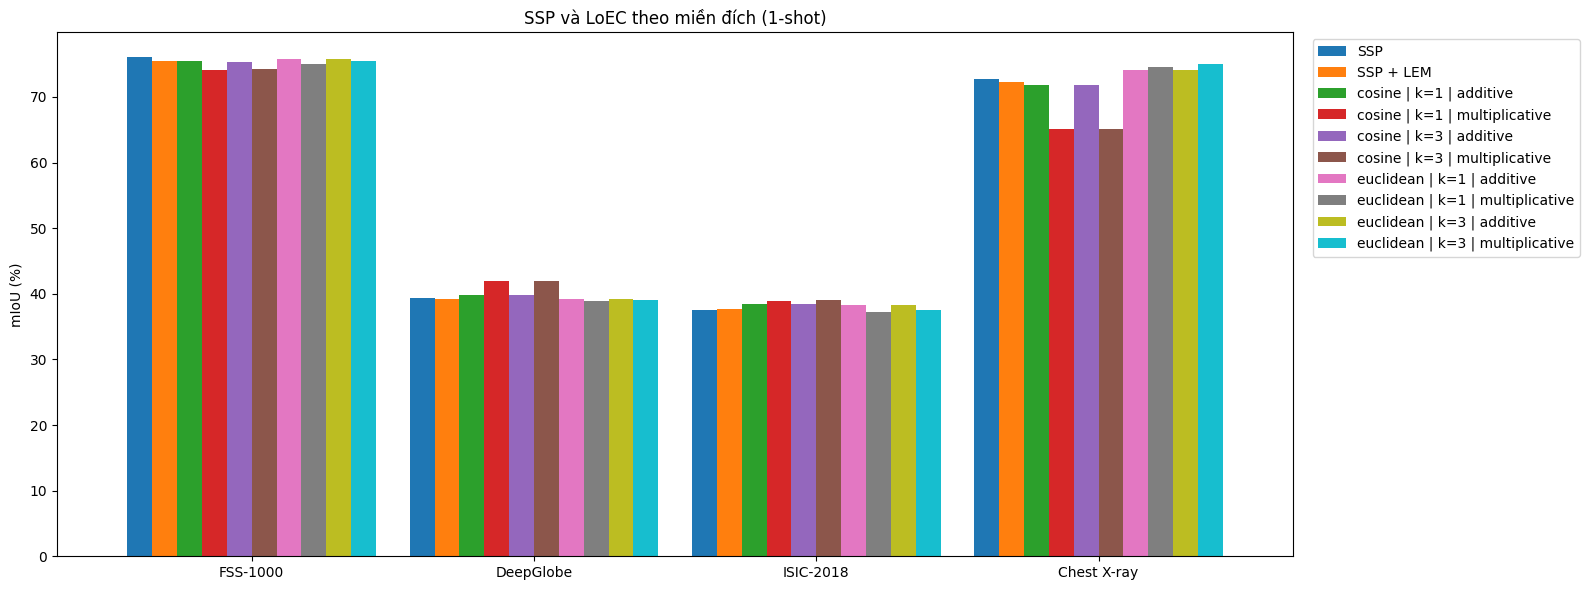

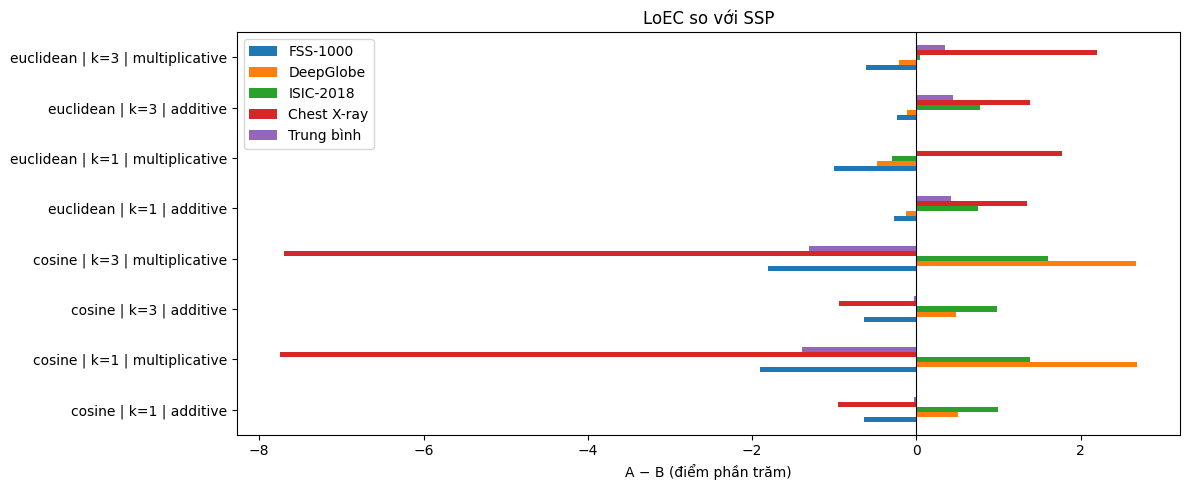

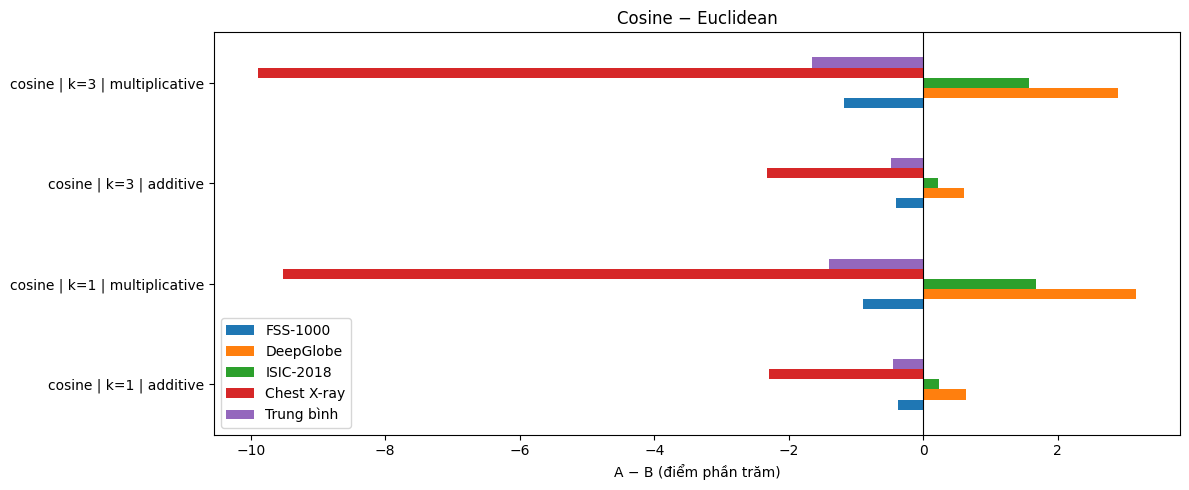

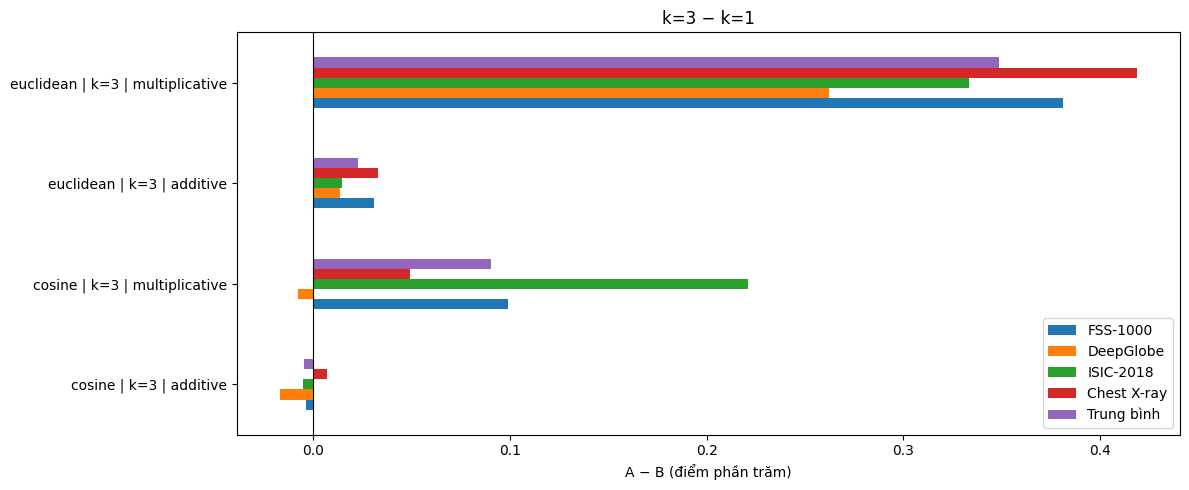

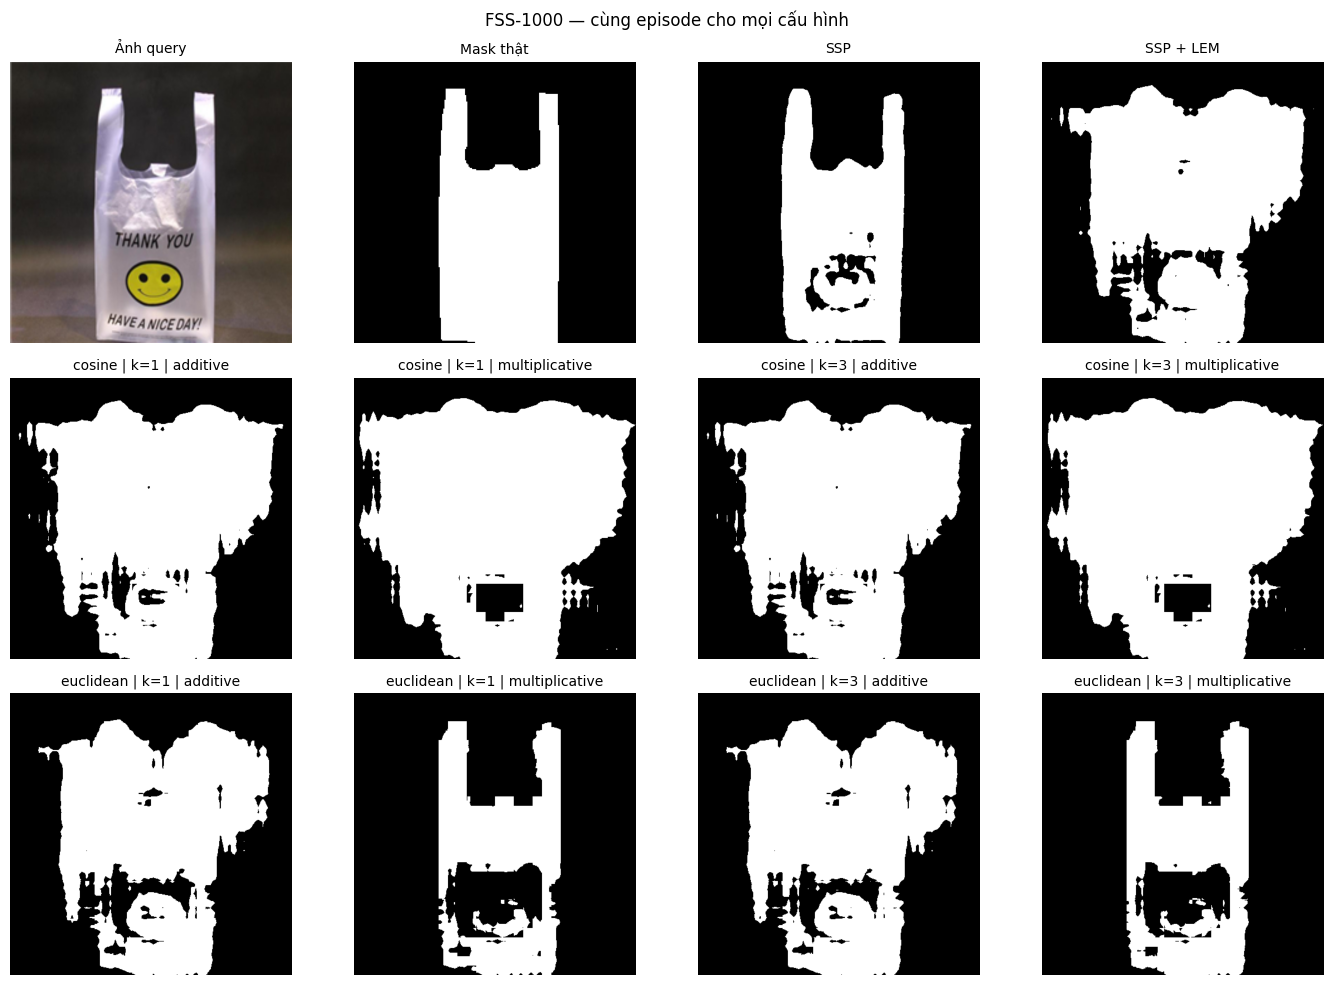

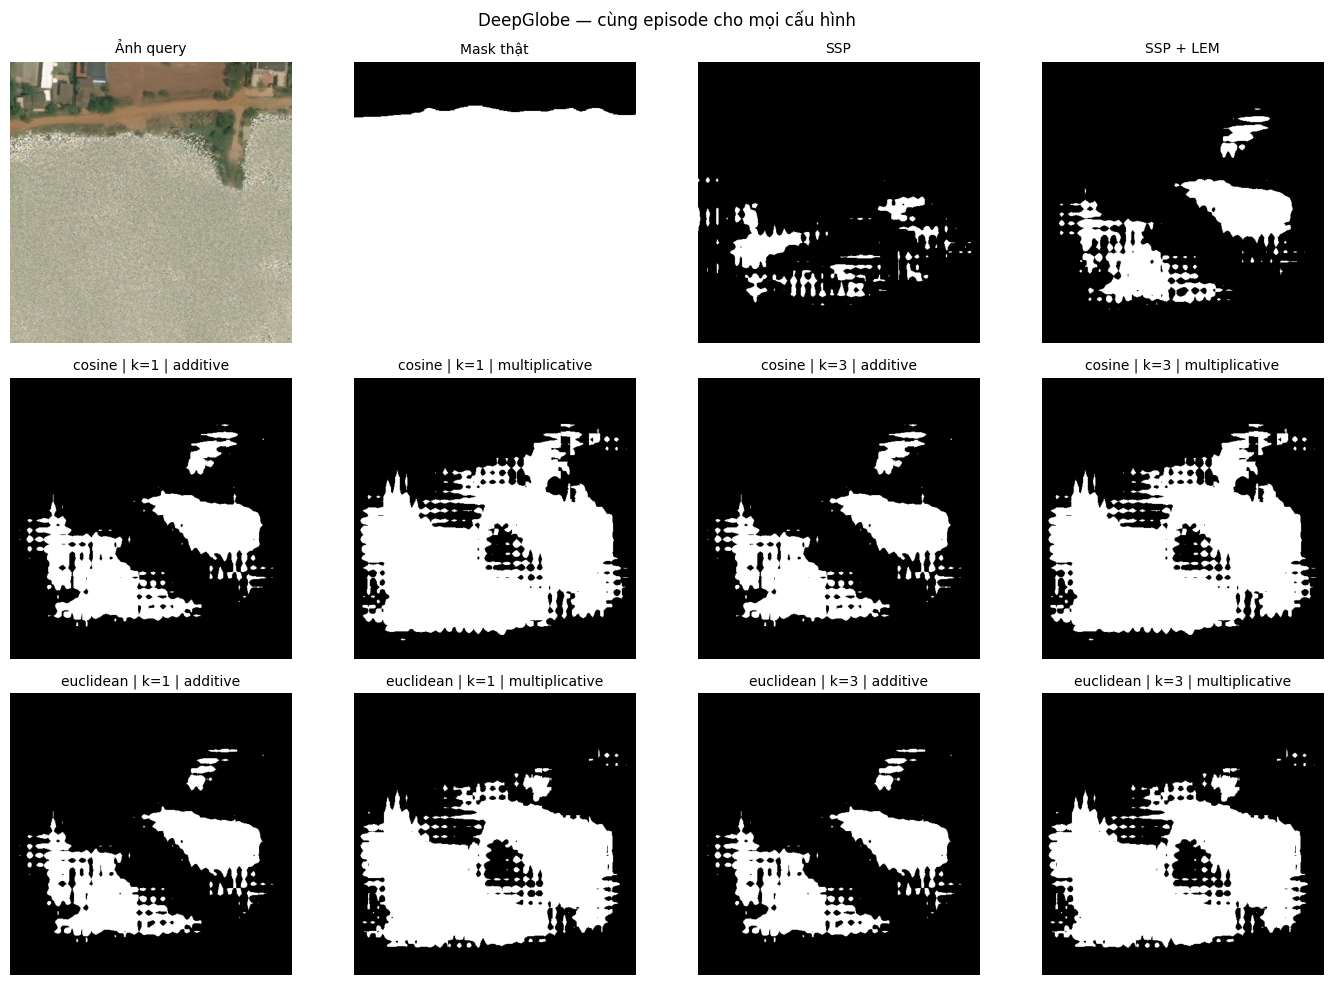

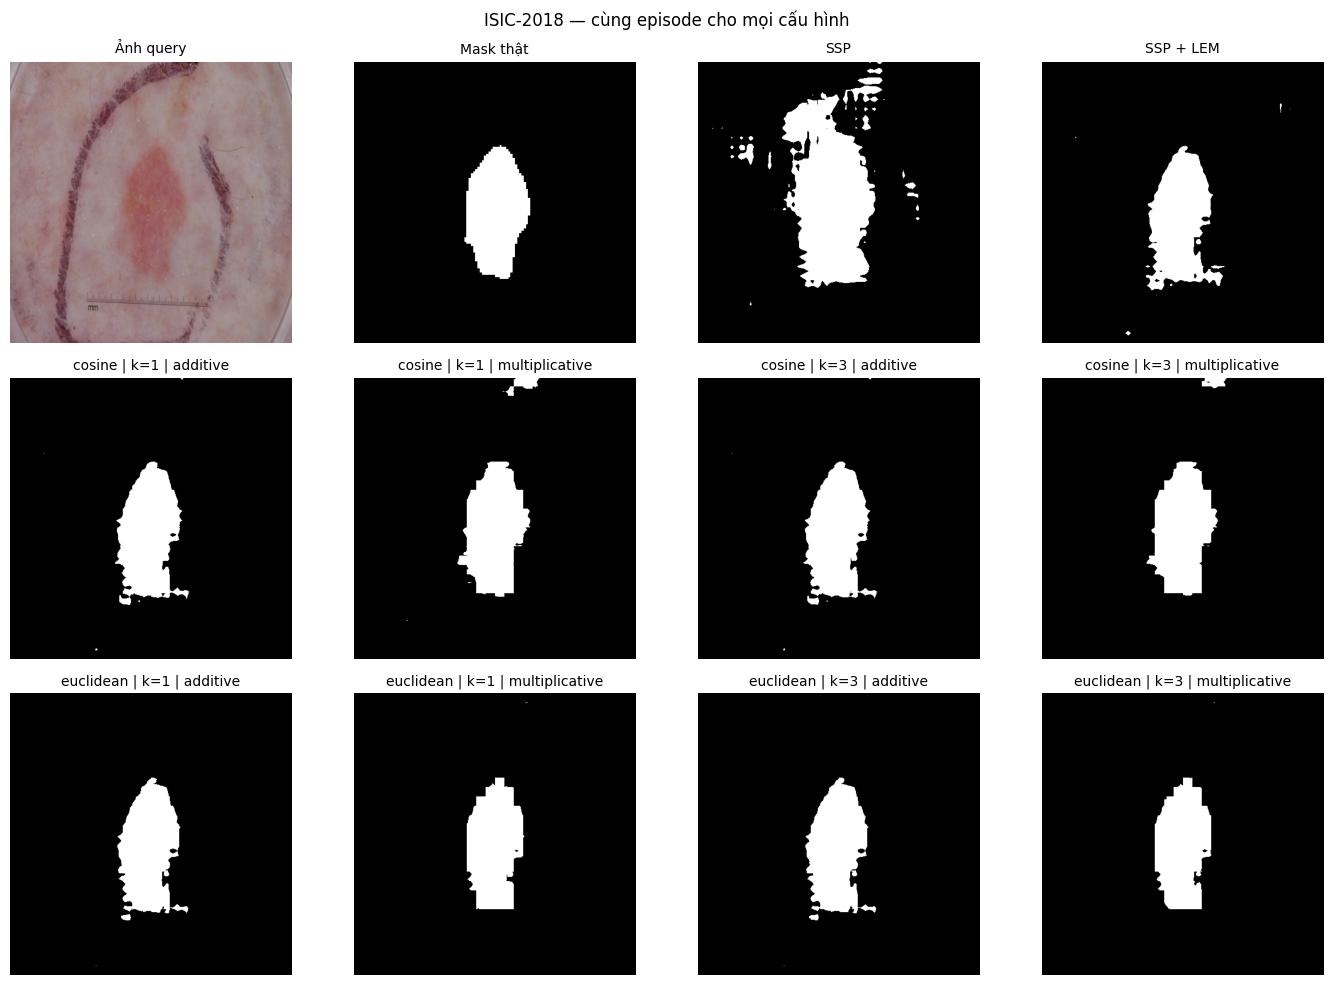

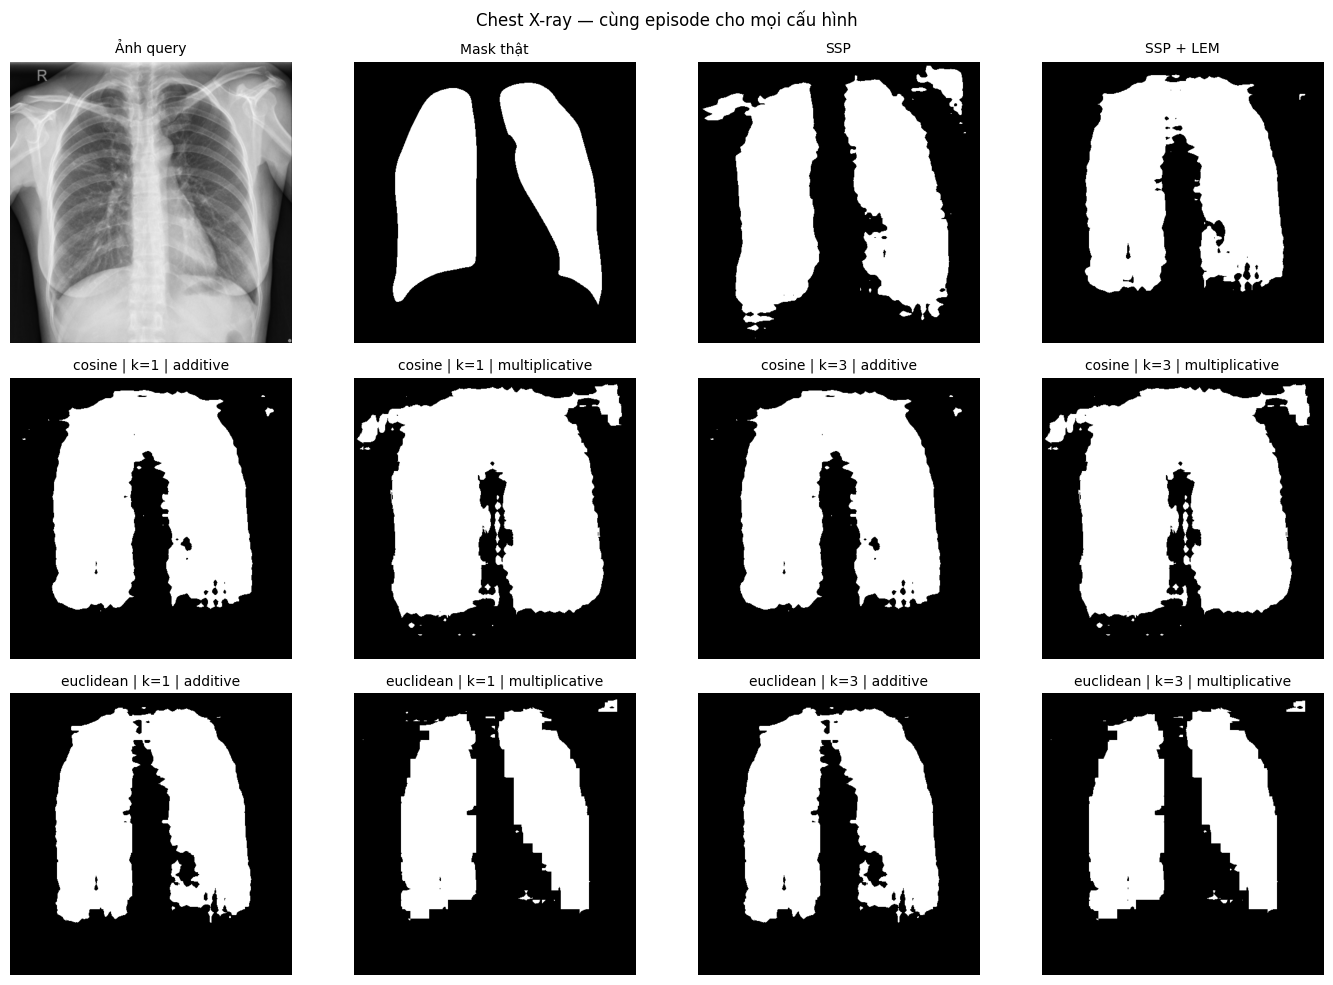

In [7]:
ax = score_table[DOMAINS].T.plot.bar(figsize=(16, 6), width=0.88)
ax.set_ylabel('mIoU (%)')
ax.set_xlabel('')
ax.set_title(f'SSP và LoEC theo miền đích ({N_SHOT}-shot)')
ax.tick_params(axis='x', rotation=0)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
ax.figure.tight_layout()
ax.figure.savefig(RESULTS / 'miou_by_domain.png', dpi=160)
plt.show()

for group in ['LoEC so với SSP', 'Cosine − Euclidean', 'k=3 − k=1']:
    rows = deltas.loc[deltas['So sánh'] == group].set_index('A')
    ax = rows[DOMAINS + ['Trung bình']].plot.barh(figsize=(12, 5))
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('A − B (điểm phần trăm)')
    ax.set_ylabel('')
    ax.set_title(group)
    ax.figure.tight_layout()
    names = {'LoEC so với SSP': 'delta_loec', 'Cosine − Euclidean': 'delta_metric', 'k=3 − k=1': 'delta_k'}
    ax.figure.savefig(RESULTS / f'{names[group]}.png', dpi=160)
    plt.show()

for domain, (batch, predictions) in examples.items():
    fig, axes = plt.subplots(3, 4, figsize=(14, 10))
    panels = [
        ('Ảnh query', batch['q_ori'][0], None),
        ('Mask thật', batch['mask_q'][0] == 1, 'gray'),
    ]
    panels += [(label, mask[0], 'gray') for label, mask in predictions.items()]
    for ax, (label, image, cmap) in zip(axes.flat, panels):
        image = image.numpy()
        if cmap is None:
            if image.shape[0] == 3:
                image = image.transpose(1, 2, 0)
            image = np.clip(image / 255 if image.max() > 1 else image, 0, 1)
        ax.imshow(image, cmap=cmap, vmin=0, vmax=1)
        ax.set_title(label, fontsize=10)
        ax.axis('off')
    fig.suptitle(f'{domain} — cùng episode cho mọi cấu hình')
    fig.tight_layout()
    fig.savefig(RESULTS / f'masks_{domain.replace(" ", "_")}.png', dpi=160)
    plt.show()